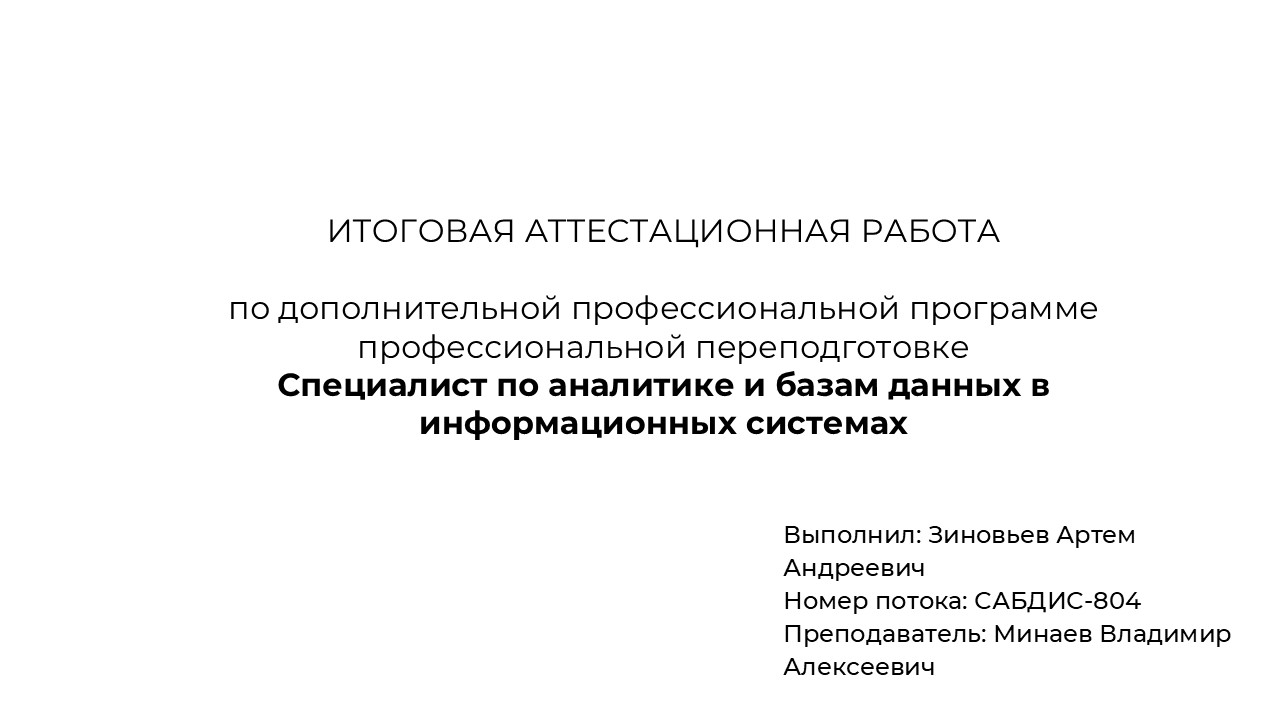


# Финальный проект: исследовательский анализ данных на основе датасета `tips`

### Описание данных

В проекте используется датасет `tips` из библиотеки `seaborn`.

Датасет содержит информацию о счетах и чаевых в ресторане. Каждая строка — это один заказ.

### Переменные датасета

| Переменная | Описание |
|---|---|
| `total_bill` | Общая сумма счета |
| `tip` | Размер чаевых |
| `sex` | Пол клиента |
| `smoker` | Курящий клиент или нет |
| `day` | День недели |
| `time` | Время посещения: обед или ужин |
| `size` | Размер компании |


# Вариант 1. Базовый EDA: счета и чаевые в ресторане

## Финальный проект: исследовательский анализ датасета `tips`

### Цель проекта

Провести базовый исследовательский анализ данных о счетах и чаевых в ресторане, изучить основные закономерности и построить статические и интерактивные визуализации.

---

## Задание 1. Загрузка данных и первичный осмотр

Загрузите датасет `tips` из библиотеки `seaborn`.

Необходимо:

1. Импортировать библиотеки:
   - `pandas`;
   - `seaborn`;
   - `matplotlib.pyplot`.
2. Загрузить датасет `tips`.
3. Вывести первые 5 строк.
4. Вывести размер датасета.
5. Посмотреть названия столбцов.
6. Проверить типы данных.

Пример:

```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset('tips')
```

Вопросы:

- Сколько строк и столбцов в датасете?
- Какие переменные числовые?
- Какие переменные категориальные?

---

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

tips = sns.load_dataset('tips')

In [2]:
display(tips.head(5))

print("\nРазмер датасета:", tips.shape, "\n")

print("Название столбцов:", tips.columns.tolist(), "\n")

print("Типы данных:")
print(tips.dtypes)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



Размер датасета: (244, 7) 

Название столбцов: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'] 

Типы данных:
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


Вывод: В результате загрузки и первичного осмотра датасета tips установлено, что он содержит 244 строки и 7 столбцов. Первые 5 строк показывают, что данные описывают заказы в ресторане: сумму счёта, размер чаевых, пол клиента, факт курения, день недели, время приёма пищи и размер компании. Типы данных корректны: три числовые переменные (total_bill, tip, size) хранятся как float64 и int64, а четыре категориальные (sex, smoker, day, time) — как category.

Ответы на вопросы:
1. В датасете 244 строки и 7 столбцов.
2. Числовые переменные: "total_bill", "tip", "size"
3. Категориальные переменные: "sex", "smoker", "day", "time"

---

## Задание 2. Проверка качества данных

Проверьте датасет на пропуски и дубликаты.

Необходимо:

1. Проверить наличие пропущенных значений.
2. Проверить количество дубликатов.
3. Проверить уникальные значения в категориальных столбцах:
   - `sex`;
   - `smoker`;
   - `day`;
   - `time`.
4. Решить, нужно ли очищать датасет.
5. Кратко описать результат проверки.

Вопросы:

- Есть ли пропуски?
- Есть ли дубликаты?
- Все ли категории выглядят корректно?

---


In [3]:
print("Пропуски по столбцам:")
print(tips.isnull().sum())

print("\nКоличество дубликатов:", tips.duplicated().sum())
print(tips[tips.duplicated(keep=False)]) # Узнаем что за дубликат

print("\nУникальные значения в категориальных столбцах:")
for col in ['sex', 'smoker', 'day', 'time']:
    print(f"  В столбце {col}: {tips[col].unique().tolist()}")

Пропуски по столбцам:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Количество дубликатов: 1
     total_bill  tip     sex smoker   day   time  size
198        13.0  2.0  Female    Yes  Thur  Lunch     2
202        13.0  2.0  Female    Yes  Thur  Lunch     2

Уникальные значения в категориальных столбцах:
  В столбце sex: ['Female', 'Male']
  В столбце smoker: ['No', 'Yes']
  В столбце day: ['Sun', 'Sat', 'Thur', 'Fri']
  В столбце time: ['Dinner', 'Lunch']


In [4]:
tips = tips.drop_duplicates().reset_index(drop=True)
print("\nКоличество дубликатов:", tips.duplicated().sum())


Количество дубликатов: 0


Вывод: По результатам проверки пропуски отсутствуют, 1 дубликат. Датасет не требует очистки. Единственное необязательное действие удаление одного дубликата. Пропусков и некорректных категорий нет, поэтому датасет готов к дальнейшему анализу и визуализации.

Ответы на вопросы:
1. Пропусков нет
2. Есть
3. Да

---

## Задание 3. Описательная статистика

Изучите числовые переменные:

- `total_bill`;
- `tip`;
- `size`.

Необходимо:

1. Получить описательную статистику.
2. Найти средний и медианный счет.
3. Найти средние и медианные чаевые.
4. Найти минимальные и максимальные значения счета и чаевых.
5. Кратко интерпретировать результаты.

Вопросы:

- Какой типичный размер счета?
- Какой типичный размер чаевых?
- Есть ли очень большие или очень маленькие значения?

---

In [5]:
numeric_cols = ['total_bill', 'tip', 'size']

print(tips[numeric_cols].describe().round(2), "\n")

print(f"Средний счёт:   {tips['total_bill'].mean():.2f}")
print(f"Медианный счёт: {tips['total_bill'].median():.2f}\n")

print(f"Средние чаевые:   {tips['tip'].mean():.2f}")
print(f"Медианные чаевые: {tips['tip'].median():.2f}\n")

print(f"Счёт:   min = {tips['total_bill'].min():.2f}, max = {tips['total_bill'].max():.2f}")
print(f"Чаевые: min = {tips['tip'].min():.2f}, max = {tips['tip'].max():.2f}\n")

       total_bill     tip    size
count      243.00  243.00  243.00
mean        19.81    3.00    2.57
std          8.91    1.39    0.95
min          3.07    1.00    1.00
25%         13.38    2.00    2.00
50%         17.81    2.92    2.00
75%         24.17    3.58    3.00
max         50.81   10.00    6.00 

Средний счёт:   19.81
Медианный счёт: 17.81

Средние чаевые:   3.00
Медианные чаевые: 2.92

Счёт:   min = 3.07, max = 50.81
Чаевые: min = 1.00, max = 10.00



Вывод: Типичный счёт около 18 долларов (медиана 17.81, среднее 19.81). Среднее выше медианы, значит есть крупные чеки, тянущие среднее вверх. Типичные чаевые около 3 долларов (медиана 2.92, среднее 3.00), значения почти совпадают. Очень большие и очень маленькие значения есть, в основном большие: счёт от 3.07 до 50.81 доллара, чаевые от 1 до 10 доллара.

Ответы на вопросы:
* Типичный счёт около 17–20 доллара.
* Типичные чаевые около 2-3 доллара.
* Да, есть, в основном большие.

---

## Задание 4. Анализ процента чаевых

Создайте новый столбец `tip_percent`.

```python
tips['tip_percent'] = tips['tip'] / tips['total_bill'] * 100
```

Необходимо:

1. Создать столбец `tip_percent`.
2. Найти средний, медианный, минимальный и максимальный процент чаевых.
3. Построить гистограмму распределения `tip_percent`.
4. Построить boxplot для `tip_percent`.
5. Сделать краткий вывод.

Вопросы:

- Какой процент чаевых встречается чаще всего?
- Есть ли необычно высокие или низкие значения?
- Отличается ли среднее от медианы?

---

Средний:   16.08%
Медианный: 15.52%
Минимум:   3.56%
Максимум:  71.03%


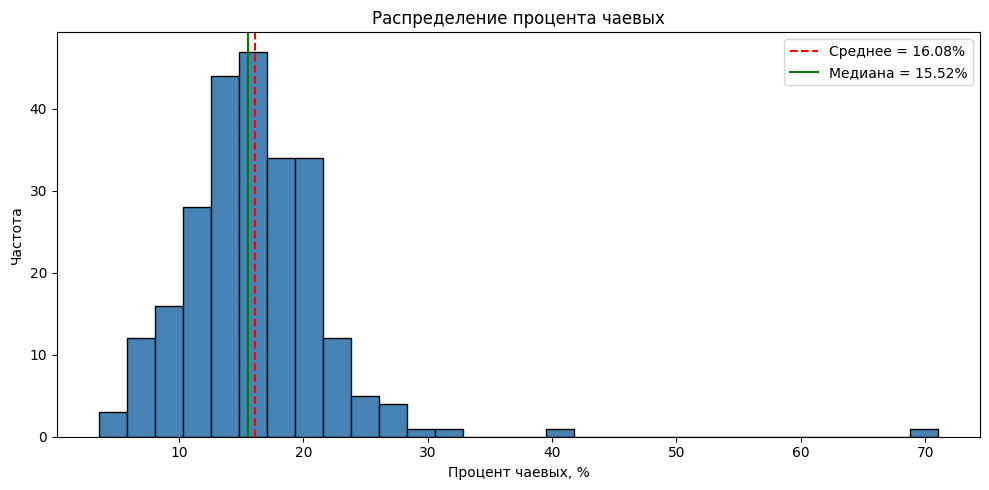

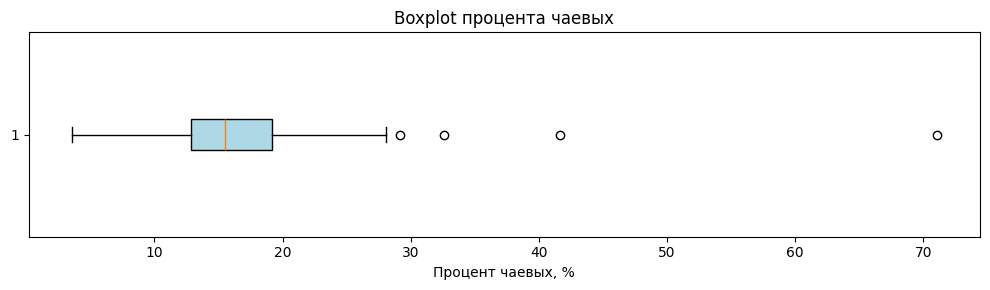

In [6]:
tips['tip_percent'] = tips['tip'] / tips['total_bill'] * 100

print(f"Средний:   {tips['tip_percent'].mean():.2f}%")
print(f"Медианный: {tips['tip_percent'].median():.2f}%")
print(f"Минимум:   {tips['tip_percent'].min():.2f}%")
print(f"Максимум:  {tips['tip_percent'].max():.2f}%")

plt.figure(figsize=(10, 5))
plt.hist(tips['tip_percent'], bins=30, edgecolor='black', color='steelblue')
plt.axvline(tips['tip_percent'].mean(), color='red', linestyle='--', label=f"Среднее = {tips['tip_percent'].mean():.2f}%")
plt.axvline(tips['tip_percent'].median(), color='green', linestyle='-', label=f"Медиана = {tips['tip_percent'].median():.2f}%")
plt.xlabel('Процент чаевых, %')
plt.ylabel('Частота')
plt.title('Распределение процента чаевых')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.boxplot(tips['tip_percent'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='lightblue'))
plt.xlabel('Процент чаевых, %')
plt.title('Boxplot процента чаевых')
plt.tight_layout()
plt.show()

Вывод: Чаще всего встречается процент чаевых в диапазоне 15-16%. Также в данных присутствуют необычные значения от 3% до 71%, что говорит о наличии выбросов как с низкой, так и с высокой стороны. При этом среднее и медиана отличаются незначительно, значит распределение процента чаевых близко к симметричному.

Ответы на вопросы:
* В среднем чаще встречается 15-16%
* Встречаются необычные значения, от 3% до 71%
* Среднее и медиана отличаются не значительно

---

## Задание 5. Сравнение чаевых по категориям

Сравните средний размер чаевых по категориям.

Необходимо рассчитать средний `tip` по:

1. `sex`;
2. `smoker`;
3. `day`;
4. `time`.

Для каждой группировки постройте столбчатую диаграмму.

Пример:

```python
tips.groupby('day')['tip'].mean()
```

Вопросы:

- В какой день средние чаевые выше?
- Кто в среднем оставляет больше чаевых: курящие или некурящие?
- Есть ли разница между обедом и ужином?

---






























In [7]:
sex = tips.groupby('sex', observed=True)['tip'].mean()
smoker = tips.groupby('smoker', observed=True)['tip'].mean()
day = tips.groupby('day', observed=True)['tip'].mean().round(2)
time = tips.groupby('time', observed=True)['tip'].mean()

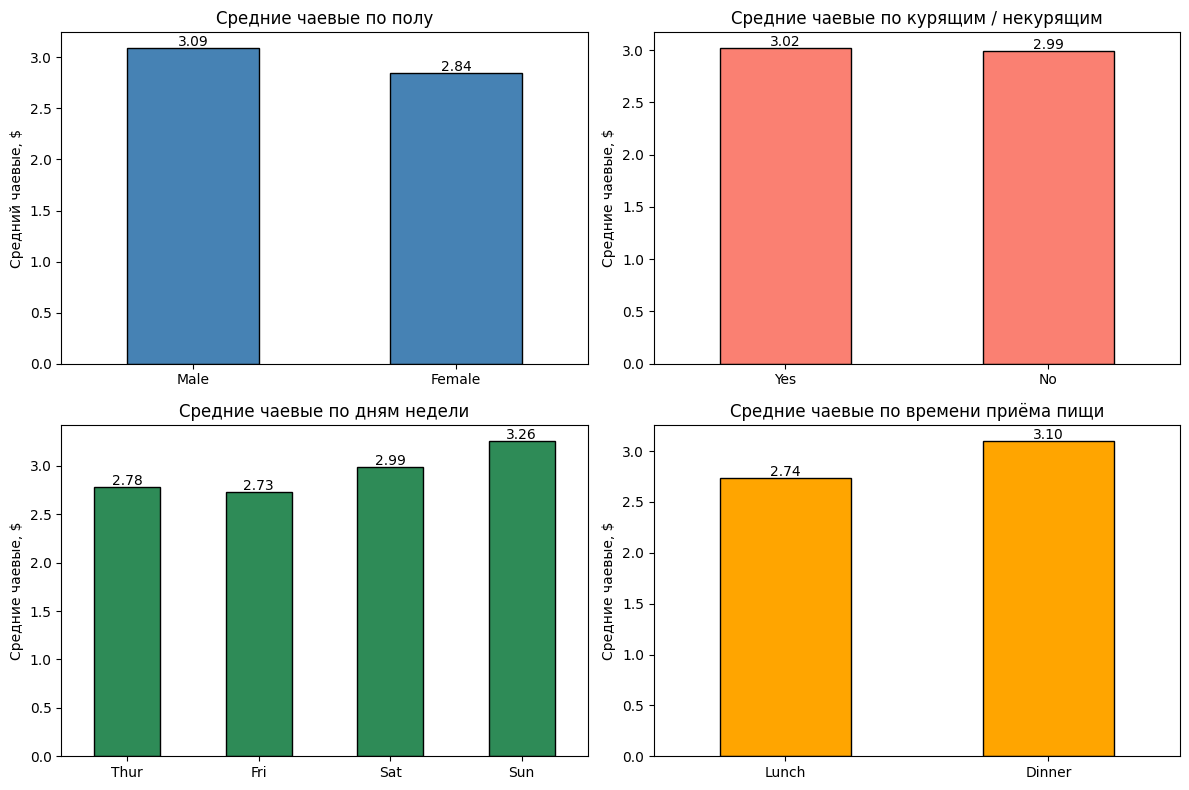

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sex.plot(kind='bar', ax=axes[0, 0], color='steelblue', edgecolor='black')
axes[0, 0].set_title('Средние чаевые по полу')
axes[0, 0].set_ylabel('Средний чаевые, $')
axes[0, 0].set_xlabel('')
axes[0, 0].tick_params(axis='x', rotation=0)
for i, v in enumerate(sex.values):
    axes[0, 0].text(i, v + 0.02, f'{v:.2f}', ha='center')

smoker.plot(kind='bar', ax=axes[0, 1], color='salmon', edgecolor='black')
axes[0, 1].set_title('Средние чаевые по курящим / некурящим')
axes[0, 1].set_ylabel('Средние чаевые, $')
axes[0, 1].set_xlabel('')
axes[0, 1].tick_params(axis='x', rotation=0)
for i, v in enumerate(smoker.values):
    axes[0, 1].text(i, v + 0.02, f'{v:.2f}', ha='center')

day.plot(kind='bar', ax=axes[1, 0], color='seagreen', edgecolor='black')
axes[1, 0].set_title('Средние чаевые по дням недели')
axes[1, 0].set_ylabel('Средние чаевые, $')
axes[1, 0].set_xlabel('')
axes[1, 0].tick_params(axis='x', rotation=0)
for i, v in enumerate(day.values):
    axes[1, 0].text(i, v + 0.02, f'{v:.2f}', ha='center')

time.plot(kind='bar', ax=axes[1, 1], color='orange', edgecolor='black')
axes[1, 1].set_title('Средние чаевые по времени приёма пищи')
axes[1, 1].set_ylabel('Средние чаевые, $')
axes[1, 1].set_xlabel('')
axes[1, 1].tick_params(axis='x', rotation=0)
for i, v in enumerate(time.values):
    axes[1, 1].text(i, v + 0.02, f'{v:.2f}', ha='center')

plt.tight_layout()
plt.show()

Вывод: Средний размер чаевых был рассчитан по четырём категориальным признакам: полу, факту курения, дню недели и времени приёма пищи. По каждой группировке построена столбчатая диаграмма. Результаты показали, что наиболее заметные различия наблюдаются по дню недели и времени приёма пищи, тогда как по полу разница небольшая, а по курению практически отсутствуют.

Ответы на вопросы:
* В воскресенье средние чаевые выше (3.26$)
* Разницы почти нет между курящими и не курящими
* На ужине оставляют больше чаевых, чем на обеде

---

## Задание 6. Связь между суммой счета и чаевыми

Исследуйте зависимость между `total_bill` и `tip`.

Необходимо:

1. Построить scatter plot:
   - X — `total_bill`;
   - Y — `tip`.
2. Добавить линию регрессии.
3. Посчитать корреляцию между `total_bill` и `tip`.
4. Сделать вывод о характере связи.

Можно использовать:

```python
sns.regplot(data=tips, x='total_bill', y='tip')
```

Вопросы:

- Есть ли связь между суммой счета и чаевыми?
- Связь слабая, средняя или сильная?
- Чем больше счет, тем больше чаевые?

---

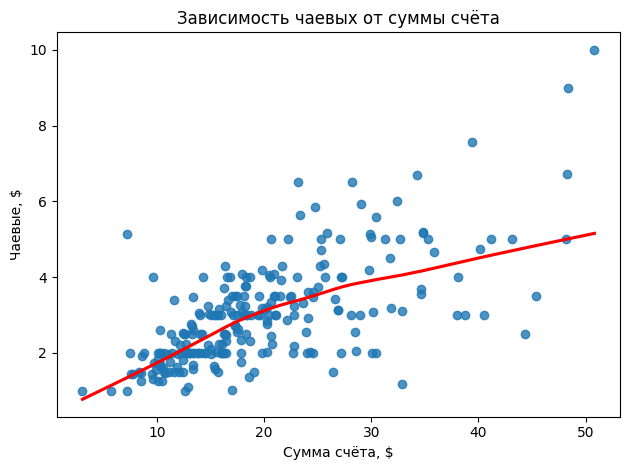

In [9]:
sns.regplot(data=tips, x='total_bill', y='tip', lowess=True, line_kws={'color': 'red'})
plt.title('Зависимость чаевых от суммы счёта')
plt.xlabel('Сумма счёта, $')
plt.ylabel('Чаевые, $')
plt.tight_layout()
plt.show()

In [10]:
print(tips[['total_bill', 'tip']].corr().round(2))

            total_bill   tip
total_bill        1.00  0.67
tip               0.67  1.00


Вывод: Между суммой счёта и чаевыми есть положительная связь. Корреляция 0.67 - это умеренная положительная связь. На графике с линией регрессии видно, что с ростом счёта чаевые в среднем растут, но разброс точек большой при одинаковом счёте чаевые могут сильно отличаться. Значит, помимо суммы счёта на размер чаевых влияют и другие факторы.

Ответы на вопросы:
* Да есть, см. вывод выше.
* Связь средняя
* Да, в среднем чем больше счёт, тем больше чаевые


---

## Дополнительное задание 7. Расширенный анализ размера компании

Изучите, как размер компании влияет на счет и чаевые.

Необходимо:

1. Найти средний `total_bill` для каждого значения `size`.
2. Найти средний `tip` для каждого значения `size`.
3. Найти средний `tip_percent` для каждого значения `size`.
4. Построить три графика зависимости:
   - `size` и `total_bill`;
   - `size` и `tip`;
   - `size` и `tip_percent`.
5. Сравнить абсолютные чаевые и процент чаевых.
6. Сделать вывод.

Вопросы:

- Увеличивается ли счет при росте размера компании?
- Увеличиваются ли чаевые?
- Меняется ли процент чаевых при увеличении компании?

---

In [11]:
mean_total_bill = tips.groupby('size', observed=True)['total_bill'].mean().round(2)
mean_tip = tips.groupby('size', observed=True)['tip'].mean().round(2)
mean_tip_percent = tips.groupby('size', observed=True)['tip_percent'].mean().round(2)

print("Средний total_bill для каждого значения size:")
print(mean_total_bill)

print("\nСредний tip для каждого значения size:")
print(mean_tip)

print("\nСредний tip_percent для каждого значения size:")
print(mean_tip_percent)

Средний total_bill для каждого значения size:
size
1     7.24
2    16.47
3    23.28
4    28.61
5    30.07
6    34.83
Name: total_bill, dtype: float64

Средний tip для каждого значения size:
size
1    1.44
2    2.59
3    3.39
4    4.14
5    4.03
6    5.22
Name: tip, dtype: float64

Средний tip_percent для каждого значения size:
size
1    21.73
2    16.58
3    15.22
4    14.59
5    14.15
6    15.62
Name: tip_percent, dtype: float64


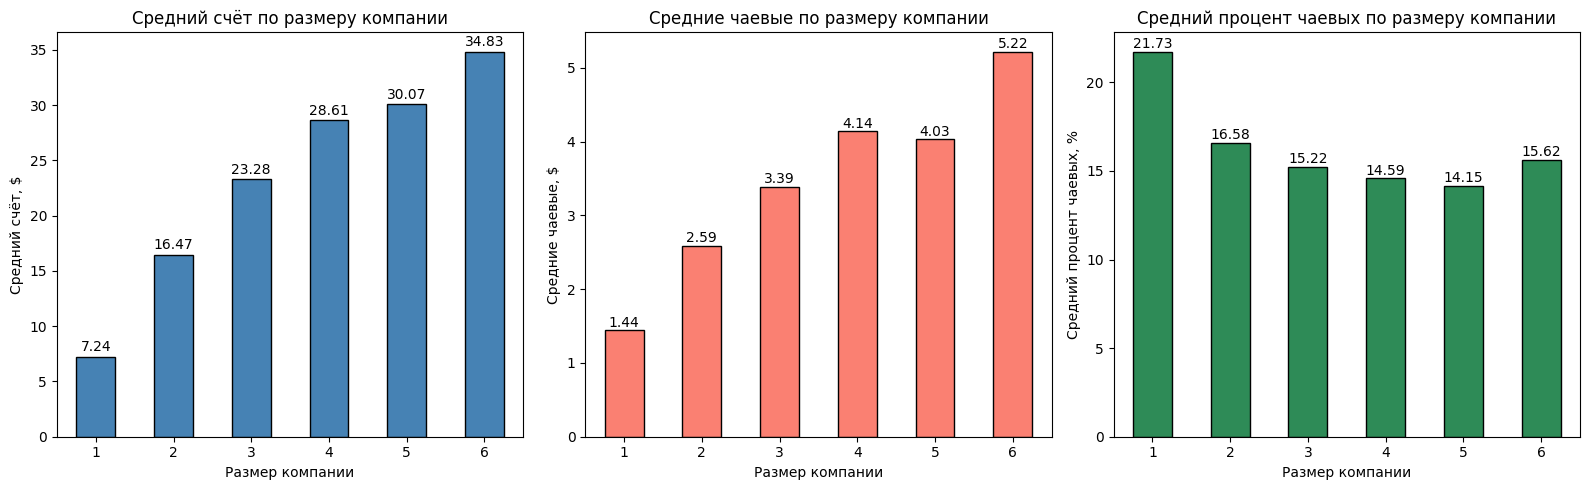

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

mean_total_bill.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Средний счёт по размеру компании')
axes[0].set_xlabel('Размер компании')
axes[0].set_ylabel('Средний счёт, $')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(mean_total_bill.values):
    axes[0].text(i, v + 0.5, f'{v:.2f}', ha='center')

mean_tip.plot(kind='bar', ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title('Средние чаевые по размеру компании')
axes[1].set_xlabel('Размер компании')
axes[1].set_ylabel('Средние чаевые, $')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(mean_tip.values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center')

mean_tip_percent.plot(kind='bar', ax=axes[2], color='seagreen', edgecolor='black')
axes[2].set_title('Средний процент чаевых по размеру компании')
axes[2].set_xlabel('Размер компании')
axes[2].set_ylabel('Средний процент чаевых, %')
axes[2].tick_params(axis='x', rotation=0)
for i, v in enumerate(mean_tip_percent.values):
    axes[2].text(i, v + 0.2, f'{v:.2f}', ha='center')

plt.tight_layout()
plt.show()

In [13]:
tip_vs_tip_percent = pd.DataFrame({
    'mean_tip': mean_tip,
    'mean_tip_percent': mean_tip_percent
})
print(tip_vs_tip_percent)

      mean_tip  mean_tip_percent
size                            
1         1.44             21.73
2         2.59             16.58
3         3.39             15.22
4         4.14             14.59
5         4.03             14.15
6         5.22             15.62


Вывод: При росте размера компании средний счёт стабильно увеличивается. Чаевые тоже растут, но медленнее. При этом процент чаевых, наоборот, падает — с ~21% для одного человека до ~14-15% для больших компаний. То есть большие компании оставляют больше денег в абсолюте, но меньший процент от счёта. Это связано с тем, что чаевые часто округляют, а в больших компаниях счёт делят между участниками.

Ответы на вопросы:
* Да, чётко и стабильно. Средний счёт растёт почти линейно
* Да, чаевые тоже растут
* Да, и в обратную сторону, процент падает

---

## Дополнительное задание 8. Интерактивная визуализация с Plotly

Добавьте интерактивные графики.

Необходимо:

1. Импортировать `plotly.express`.
2. Построить интерактивный scatter plot:
   - `x='total_bill'`;
   - `y='tip'`;
   - цвет точек — `day`;
   - размер точек — `size`;
   - hover-подсказки: `sex`, `smoker`, `time`, `tip_percent`.
3. Построить интерактивную столбчатую диаграмму среднего размера чаевых по дням недели.
4. Построить интерактивный boxplot `tip_percent` по `day`.
5. Кратко описать, чем интерактивные графики удобнее обычных.

Пример:

```python
import plotly.express as px

fig = px.scatter(
    tips,
    x='total_bill',
    y='tip',
    color='day',
    size='size',
    hover_data=['sex', 'smoker', 'time', 'tip_percent'],
    title='Связь между суммой счета и чаевыми'
)

fig.show()
```

---


In [19]:
import plotly.express as px

fig_scatter = px.scatter(
    tips,
    x='total_bill',
    y='tip',
    color='day',
    size='size',
    labels={'tip': 'Средние чаевые, $', 'total_bill': 'Итоговый счёт'},
    hover_data=['sex', 'smoker', 'time', 'tip_percent'],
    title='Связь между суммой счёта и чаевыми'
)

fig_scatter.show()

mean_tip_by_day = tips.groupby('day', observed=True)['tip'].mean().reset_index()

fig_bar = px.bar(
    mean_tip_by_day,
    x='day',
    y='tip',
    title='Средние чаевые по дням недели',
    labels={'tip': 'Средние чаевые, $', 'day': 'День недели'},
    color='day',
    text_auto='.2f'
)

fig_bar.show()

fig_box = px.box(
    tips,
    x='day',
    y='tip_percent',
    color='day',
    title='Распределение процента чаевых по дням недели',
    labels={'tip_percent': 'Процент чаевых, %', 'day': 'День недели'}
)

fig_box.show()

Вывод: Интерактивные графики удобнее статичных, при наведении видно все детали точки, можно зумить и панорамировать, кликом по легенде скрывать и показывать группы, экспортировать в PNG или HTML и делиться ссылкой. Это делает анализ быстрее и нагляднее, особенно при большом числе наблюдений.

---
### Общий итоговый вывод по проекту:

На основе анализа датасета tips можно сделать следующие выводы:

1. Датасет содержит 244 записи о заказах в ресторане; пропусков нет, обнаружен и удалён один полный дубликат, после очистки — 243 записи.

2. Числовые переменные: total_bill, tip, size; категориальные: sex, smoker, day, time.

3. Типичный счёт — около 18–20$ (медиана 17.81, среднее 19.81).

4. Типичные чаевые — около 3$ (медиана 2.92, среднее 3.00).

5. Распределения счёта и чаевых скошены вправо: есть крупные чеки (до 50.81) и крупные чаевые (до 10.00) и крупные чаевые (до 10.00) это реальные заказы, а не ошибки.

6. Средний процент чаевых ≈ 16%, медианный ≈ 15.5%, что соответствует норме 15–20%.

7. Процент чаевых тоже скошен вправо: чаще всего 15–18%, но встречаются значения от 3.6% до 71%.

8. Между суммой счёта и чаевыми есть заметная положительная связь.

9. Связь не жёсткая: при одинаковом счёте чаевые могут сильно отличаться, значит есть другие влияющие факторы.

10. Главные факторы, влияющие на средние чаевые:
* День недели
* Время приёма пищи
* Размер компании.

11. Пол и курение почти не влияют на средние чаевые.

12. С ростом компании средний счёт растёт почти линейно.

13. Абсолютные чаевые тоже растут с размером компании, но медленнее, чем счёт.

14. Процент чаевых, наоборот, падает с ростом компании.

15. Большие компании оставляют больше денег в абсолюте, но меньшую долю от счёта.

16. Интерактивные графики Plotly удобнее статичных: дают hover-подсказки, зум, фильтрацию по легенде и экспорт, что ускоряет анализ.